# L'apprentissage non supervisé : le Clustering
*Cours Machine Learning - Philippe Bonny @2022*

<img src="https://drive.google.com/thumbnail?id=1giKMVn4Zra6SAlRdp5Rf5z6Wg8XgNZmu&sz=w1000">

**Données**
- générées

**Algorithmes** :
- KMeans
- Clustering hiérarchique (ou agglomératif)
- DBScan

**Méthodes de réglage des hyper-paramètres** :
- Courbe Elbow
- Silhouettes
- Instabilités
- k-Graph

# UTILITAIRES

### Ressources de calcul

In [0]:
vm="Azure Standard D4ds_v5 (4 cores, 16Gb)"
print(f"VM : {vm}")

# Databricks runtime version
import os
print("DATABRICKS_RUNTIME_VERSION:",os.environ.get('DATABRICKS_RUNTIME_VERSION',None))

#Python version
!python -V 

VM : Azure Standard D4ds_v5 (4 cores, 16Gb)
DATABRICKS_RUNTIME_VERSION: 16.4
Python 3.12.3


### Imports

In [0]:
%pip install threadpoolctl==3.1.0 Jinja2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/134.9 kB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 134.9/134.9 kB 4.0 MB/s eta 0:00:00
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
dbutils.library.restartPython()

In [0]:
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_samples
from scipy.cluster.hierarchy import dendrogram

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
import seaborn as sns

from scipy.interpolate import make_interp_spline

In [0]:
# desactivate mlflow autolog
import mlflow
mlflow.autolog(disable=True)

### Fonctions 

In [0]:
def show_2D_points(x,y, title='Représentation 2D des observations', xlabel=None, ylabel=None):
    with plt.style.context('seaborn-v0_8'):
        plt.scatter(x, y,  c='blue', marker='o', edgecolor='black', s=50)
        plt.grid(color='white')
        plt.xlabel(xlabel) if (xlabel) else plt.xlabel(xlabel)
        plt.title(title)
        plt.tight_layout()
        plt.show()

def show_n_2D_points(nX, title='Représentation 2D des observations', xlabel=None, ylabel=None, cmap=''):
    
    with plt.style.context('seaborn-v0_8'):
        for X in nX:
            plt.scatter(X[:,0], X[:,1], marker='o', alpha=0.8, s=50)
        plt.grid(color='white')
        plt.xlabel(xlabel) if (xlabel) else plt.xlabel(xlabel)
        plt.title(title)
        plt.tight_layout()
        plt.show()
    

def show_kmeans_2D_graph(km, X):
    
    k = km.n_clusters
    y_km = km.fit_predict(X)
    
    with plt.style.context('seaborn-v0_8'):
        # show cluster points
        for i in range(k):
            plt.scatter(X[y_km == i, 0],
                    X[y_km == i, 1], s=50,
         #           c=colors[i],
                    marker='s', edgecolor='black',
                    label='cluster %i' % i)

        # show cluster centers
        plt.scatter(km.cluster_centers_[:, 0],
                    km.cluster_centers_[:, 1],
                    s=250, marker='*',
                    c='red', edgecolor='black',
                    label='centroids')

        plt.legend(scatterpoints=1)
        plt.grid(color='white')
        plt.tight_layout()
        plt.title("Clusterisation KMeans")
        #plt.savefig('images/11_02.png', dpi=300)
        plt.show()

        
def show_elbow_graph(clusterer, X, para_name, para_min, para_max):
    inertie = []
    
    ran = np.arange(para_min, para_max,1)
    
    for i in ran:
        para_dic = {para_name: i}
        clusterer.set_params(**para_dic)
        clusterer.fit(X)
        inertie.append(clusterer.inertia_)
    with plt.style.context('seaborn-v0_8'):
        plt.plot(ran, inertie, marker='o')
        plt.xlabel('Number of clusters')
        plt.ylabel('Inertie')
        plt.tight_layout()
        plt.title('Courbe d\'Elbow')
        #plt.savefig

        
def show_silhouette_graph(clusterer, X, para_name, para_min, para_max, 
                         num=False, metric='euclidean'):
    
    """
    Plot a silhouette graph as a function of a clustering model parameter
    @PhBonny
    
    Parameters
    ----------
    clusterer : model
        scikit learn clustering model
    
    X : array-like
        Dataset
    
    para_name : string
        parameter name
    
    para_min : int or float
        parameter minimum value
    
    para_max : int or float
        parameter maximum value
        
    num : [Optional] int, Defaut = 50
        number of points o
        
    metric : string
        silhouette calculation metric
    """

    
    if (para_min is int):
        ran = np.arange(para_min, para_max,1)
    else:
        num = num if(num) else 50
        ran = np.linspace(para_min, para_max, num)
        
    sil = []
    for v in ran:
        para_dic = {para_name: v}
        clusterer.set_params(**para_dic)
        y = clusterer.fit_predict(X)
        sim = np.mean(silhouette_samples(X, y, metric=metric))
        sil.append(sim)
        
    with plt.style.context('seaborn-v0_8'):
        plt.plot(ran, sil, marker='o')
        plt.xlabel(para_name)
        plt.ylabel('Silhouette moyenne')
        plt.tight_layout()
        plt.title('Silhouettes en fonction de %s (%s)' % (para_name,metric))
        #plt.savefig

        
def show_silhouettes_shapes(clusterer, X, metric='euclidean'):
    y_km = clusterer.fit_predict(X)

    # Préparation des données pour l'affichage des silhouettes
    cluster_labels = np.unique(y_km)
    n_clusters = cluster_labels.shape[0]
    silhouette_vals = silhouette_samples(X, y_km, metric=metric)
    y_ax_lower, y_ax_upper = 0, 0
    
    with plt.style.context('seaborn-v0_8'):
        yticks = []
        for i, c in enumerate(cluster_labels): # enumerate permet de récupérer un compteur ici 'i'
            c_silhouette_vals = silhouette_vals[y_km == c]
            c_silhouette_vals.sort()
            y_ax_upper += len(c_silhouette_vals)
            color = cm.jet(float(i) / n_clusters)
            plt.barh(range(y_ax_lower, y_ax_upper), c_silhouette_vals, height=1.0, 
                     edgecolor='none', color=color)

            yticks.append((y_ax_lower + y_ax_upper) / 2.)
            y_ax_lower += len(c_silhouette_vals)

        silhouette_avg = np.mean(silhouette_vals)

        # Affichage des résultats
        plt.axvline(silhouette_avg, color="red", linestyle="--") 

        plt.yticks(yticks, cluster_labels + 1)
        plt.ylabel('Cluster')
        plt.xlabel('Silhouette')
        plt.title("Graphe des silhouettes")
        plt.tight_layout()
        #plt.savefig('images/11_04.png', dpi=300)
        plt.show()


def show_dendrogram(model,X, level_max=5):
    model = model.fit(X)

    # Create linkage matrix and then plot the dendrogram

    # create the counts of samples under each node
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1  # leaf node
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack(
        [model.children_, model.distances_, counts]
    ).astype(float)

    # Plot the corresponding dendrogram
    with plt.style.context('seaborn-v0_8'):
        dendrogram(linkage_matrix, truncate_mode="level", p=level_max)
        plt.title("Hierarchical Clustering Dendrogram")
        plt.xlabel("Number of points in node (or index of point if no parenthesis).")
        plt.tight_layout()
        plt.show()

        
def show_model_2D_graph(clusterer, X, legend_loc='upper right', colormap='Set1'):
    
    """
    Plot a 2D graph, based on a two dimensional dataset and an instance of a clusterer
    @PhBonny
    
    Parameters
    ----------
    clusterer : model instance
        scikit learn clustering model instance
    
    X : array-like
        Dataset
        
    legend_loc : string
        matplot lib legend position argument
        
    colormap : string
        matplotlib colormap name
    """

    l = clusterer.fit_predict(X)
    n = len(np.unique(l))
    x = X[:,0]
    y = X[:,1]
    
    with plt.style.context('seaborn-v0_8'):
        fig, ax = plt.subplots()
        scatter = ax.scatter(x,y,c=l,cmap=colormap,alpha=0.6)
        legend = ax.legend(*scatter.legend_elements(),
                        loc=legend_loc, title="Clusters")
        ax.add_artist(legend)
        plt.tight_layout()
        plt.show()

def interp(x,y,n=100):
    spline = make_interp_spline(x,y)
    x_ = np.linspace(x.min(), x.max(), n)
    y_ = spline(x_)
    return x_,y_
        
        
def show_instability_graph(instabilities, param_name, param_range, smooth=False):
     with plt.style.context('seaborn-v0_8'):
        if (smooth) :
            param_range, instabilities=interp(param_range, instabilities)
            marker = None
        else:
            marker='o'
        plt.plot(param_range, instabilities, marker=marker)
        plt.xlabel(param_name)
        plt.ylabel('Instabilités')
        plt.title('Instabilité du modèle en fonction du paramètre %s' % param_name)
        plt.tight_layout()
        plt.show()
    

def show_instas_clusters_param(param_range, instabilities, n_clusters):
    with plt.style.context('seaborn-v0_8'):
        #plt.rcParams["figure.figsize"] = (10,3)
        fig, (ax1, ax2) = plt.subplots(1, 2)
        fig.suptitle('Performance de clusterisation')

        ax1.plot(param_range, instabilities, marker='o')
        ax1.set_xlabel(param_name)
        ax1.set_ylabel('Instabilités')

        ax2.plot(param_range, n_clusters, marker='o')
        ax2.set_xlabel(param_name)
        ax2.set_ylabel('n_clusters')

        plt.tight_layout()
        #plt.savefig('images/11_03.png', dpi=300)
        plt.show()


def show_instas_clusters_outliers(param_range, instabilities, n_clusters, n_outliers):
    with plt.style.context('seaborn-v0_8'):
        plt.rcParams["figure.figsize"] = (16,6)
        fig, (ax1, ax2, ax3) = plt.subplots(1, 3)
        fig.suptitle('Performance de clusterisation')

        ax1.plot(param_range, instabilities, marker='o')
        ax1.set_xlabel(param_name)
        ax1.set_ylabel('Instabilités')

        ax2.plot(param_range, n_clusters, marker='o')
        ax2.set_xlabel(param_name)
        ax2.set_ylabel('n_clusters')

        ax3.plot(param_range, n_outliers, marker='o')
        ax3.set_xlabel(param_name)
        ax3.set_ylabel('n_outliers')
        
        plt.tight_layout()
        #plt.savefig('images/11_03.png', dpi=300)
        plt.show()


def show_k_graph_dist(distances, xlim=False, ylim=False):
    with plt.style.context('seaborn-v0_8'):
        plt.plot(distances)
        plt.xlim(xlim) if (xlim) else None
        plt.ylim(ylim) if (ylim) else None
        plt.xlabel("nb of points")
        plt.ylabel('k-distance')
        plt.grid(visible=True)
        plt.tight_layout()
        plt.title("Graphe k-distance")
        

def hiera_show_repartition(param_range):
    tmp = []
    for dist in param_range:
        hiera.distance_threshold=dist
        y = hiera.fit_predict(X)
        unique, counts = np.unique(y, return_counts=True)
        row = []
        tmp.append([dist, hiera.n_clusters_, counts])
    return pd.DataFrame(tmp, columns=['distance_threshold', 
                               'n_clusters', 'Répartition']).style.hide(axis='index')

def dbscan_show_repartition(param_range):
    tmp = []
    for eps in param_range:
        dbscan.eps=eps
        y = dbscan.fit_predict(X)
        unique, counts = np.unique(y, return_counts=True)
        nclust = len(unique)-1
        rep = counts[1:]
        out = counts[0]
        tmp.append([eps, nclust, rep, out])
    return pd.DataFrame(tmp, columns=['eps', 'n_clusters', 'Répartition', 'Outliers']).style.hide(axis='index')

In [0]:
from sklearn.metrics.pairwise import pairwise_distances
def instability(data, clusterer, param_name, param_range, n_perturbed=10, cov_div=4):
    
    """
    Calcul d'une courbe d'instabilité d'un modèle de clustering.
    Source : d'après, Cluster stability: an overview, Von Luxburg U., arXiv 1007:1075v1, 2010
    
    Parameters
    ----------
    data : numpy array
    
    clusterer : 
        An instance of clusterer model
        
    param_name : string
        Name of the target model parameter
    
    param_range : list or numpy array
        Range of variation of the parameter
    
    n_perturbed : [optional] int, default=10
        The number of generated perturbed datasets
    
    cov_dir : [optional] int, default=4
        The division value of the data covariance

    
     Returns
    -------
    instabilities : ndarray of shape (param_range,)
        Calculated instabilities per param_value

    n_clusters : ndarray of shape (param_range,)
        Number of identified clusters per param_value
    
    n_outliers : ndarray of shape (param_range,)
        Number of identified outlier (if any) per param_value
    """
    
    
    n_data = []

    data_mean = np.mean(data, axis=0)
    data_cov = np.cov(data.T) / cov_div

    for i in range(n_perturbed):
        gaussian_noise = np.random.multivariate_normal(data_mean, data_cov, size=(data.shape[0], ))
        noise = gaussian_noise * np.random.uniform(0.0, 1.0, size=(data.shape[0], data.shape[1]))
        n_data.append(data.copy() + noise)
    
    
    instabilities = []
    n_clusters = []
    n_outliers = []
    
    for param_value in param_range:
        Yn = []
        Nc = []
        Ou = []
    
        for nd in n_data:
            dict={param_name: param_value}
            ds = clusterer.set_params(**dict)
            y = ds.fit_predict(nd)
            
            Yn.append(y)
            Nc.append(len(np.unique(Yn)))
            Ou.append(len(y[ y < 0.]))
            

        distances = []

        for i in range(len(Yn)-1):
            for j in range(i, len(Yn)):
                d = pairwise_distances(Yn[i].reshape(-1, 1), Yn[j].reshape(-1, 1), 'hamming')
                distances.append(d[0, 0])

        instability = (2.0 * np.sum(distances)) / float(n_perturbed ** 2)
        n_cluster = np.mean(Nc)
        n_outlier = np.mean(Ou)
        
        instabilities.append(instability)
        n_clusters.append(n_cluster)
        n_outliers.append(n_outlier)
    
    return n_data, instabilities, n_clusters, n_outliers


from sklearn.neighbors import NearestNeighbors
def k_graph_dist(data, n_neighbors=20):
    """
    Calcul des k-graph distances
    Source : d'après, https://medium.com/@tarammullin/dbscan-parameter-estimation-ff8330e3a3bd
    
    Parameters
    ----------
    n_neighbors : int
        Number of neighbors
    
    data : ndarray
        Dataset
        
     Returns
    -------
    distances : ndarray of shape (data,)
        k-graph distances sort by value asc
    """

    neighbors = NearestNeighbors(n_neighbors=n_neighbors)
    neighbors_fit = neighbors.fit(data)
    distances, indices = neighbors_fit.kneighbors(data)
    
    distances = np.sort(distances, axis=0)
    distances = distances[:,1]
    return distances

# LE CLUSTERING CONVEXE

## Génération de clusters convexes
- Le jeux de données est 2D ici pour représentation graphique aisée 
- On utilise une fonction de génération de 'tâches' (*blobs*) isotropiques (mêmes caractéristiques dans toutes les directions)  gaussiennes pour le Clustering (plus d'info ?make_blobs).

In [0]:
X, y = make_blobs(n_samples=150,
                  n_features=2,
                  centers=3,
                  cluster_std=0.7,
                  shuffle=True,
                  random_state=0)

Affichage du jeux de données

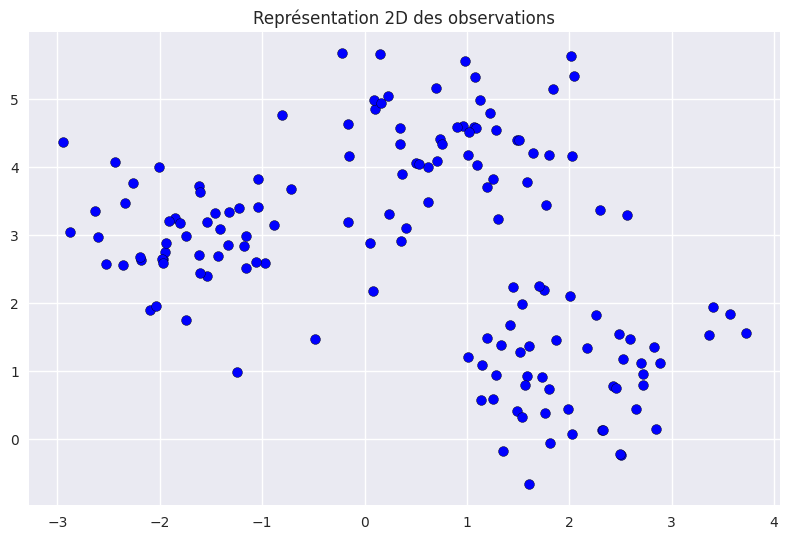

In [0]:
show_2D_points(X[:,0], X[:,1])

## Clusterisation KMeans

### Instanciation du modèle

In [0]:
from sklearn.cluster import KMeans

#?KMeans
km = KMeans(n_clusters=2, 
            init='random', 
#            init='k-means++',
            n_init=10, 
            max_iter=300,
            tol=1e-04,
            random_state=0)

y_km = km.fit_predict(X)

?KMeans

Remarques : 
- le paramètre "tol" représente le seuil de variation de l'inertie ou SSE (somme du carré des erreurs) entre deux itérations. Si ce seuil est atteint avant max_iter le programme stoppe.
- il faut veiller à avoir des variables prédictives de même ordre de grandeur (standardisation ou min-max)

Affichage des résultats du k-means

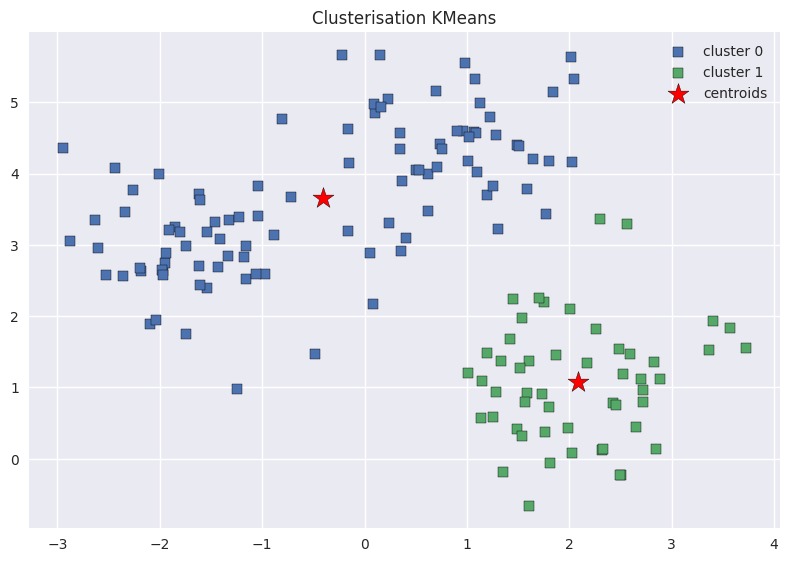

In [0]:
show_kmeans_2D_graph(km, X)

Remarques :
- l'alternative K-means++ s'obtient en remplaçant le paramètre 'init' avec 'k-means++' (pas critique ici)
- l'approche FCM pas implémentée dans scikit-learn

### Réglage - Méthode Elbow

On peut estimer l'inertie du modèle (ou distorsion, plus parlant ...) à l'aide de la moyenne des inerties de chaque clusters qui est implémentée dans scikit-learn :

In [0]:
print('Inertie: %.2f' % km.inertia_)

Inertie: 350.33


On peut évaluer graphiquement le nombre optimal, en faisant varier ici le nbre de clusters :

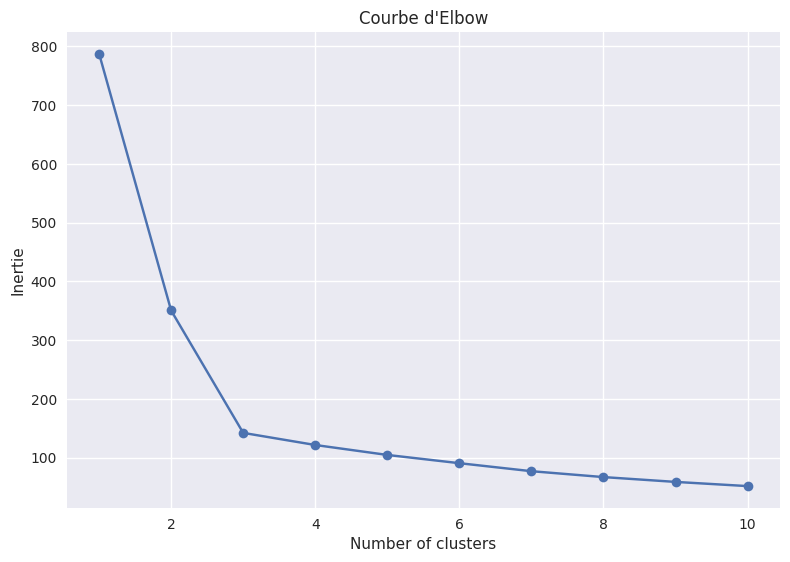

In [0]:
km = KMeans(init='k-means++', n_init=10, max_iter=300, random_state=0)
show_elbow_graph(km, X, 'n_clusters', 1, 11)

On vérifie ici que k=3 est le bon nombre de clusters dans ce cas.

<a id='silhouette'></a>

### Réglage - Méthode des Silhouettes

Création des silhouettes associées au modèle de clustering à 3 clusters ; utilisation de la fonction scikit-learn *silhouette_samples*.

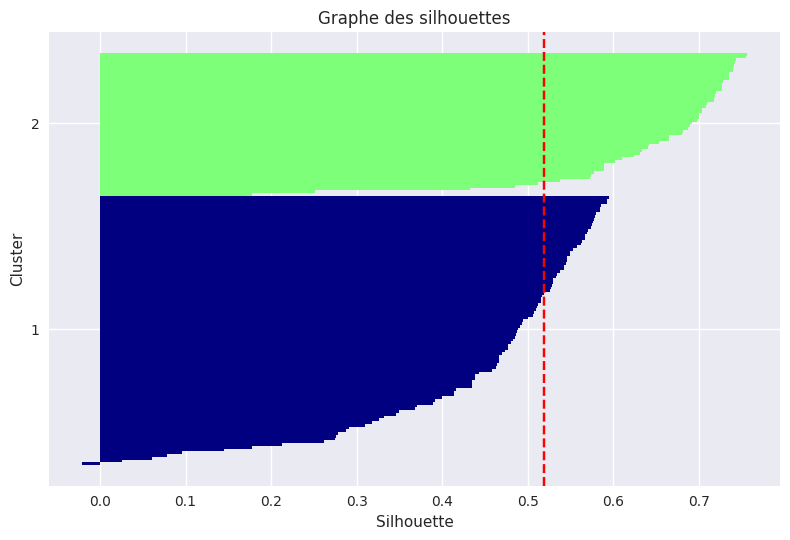

In [0]:
km = KMeans(n_clusters=2, random_state=0)
show_silhouettes_shapes(km, X)

### Cas d'une mauvaise clusterisation

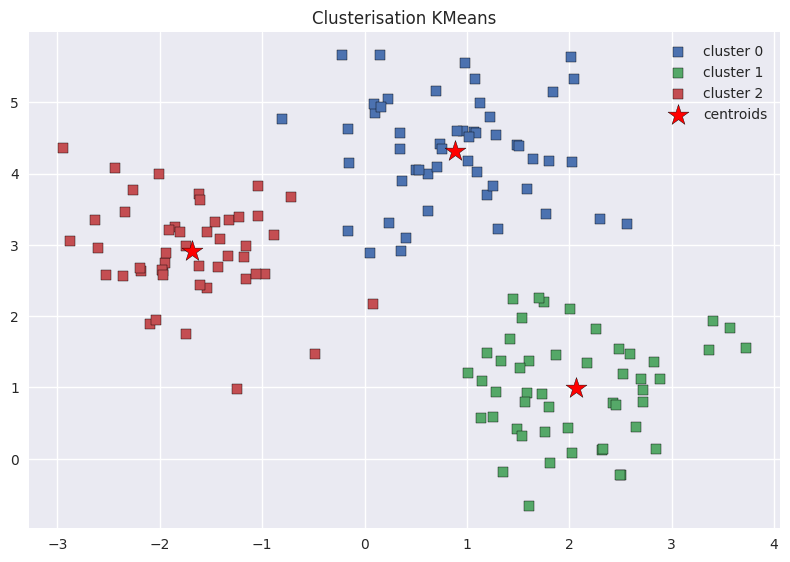

In [0]:
km.set_params(n_clusters=3)
show_kmeans_2D_graph(km,X)

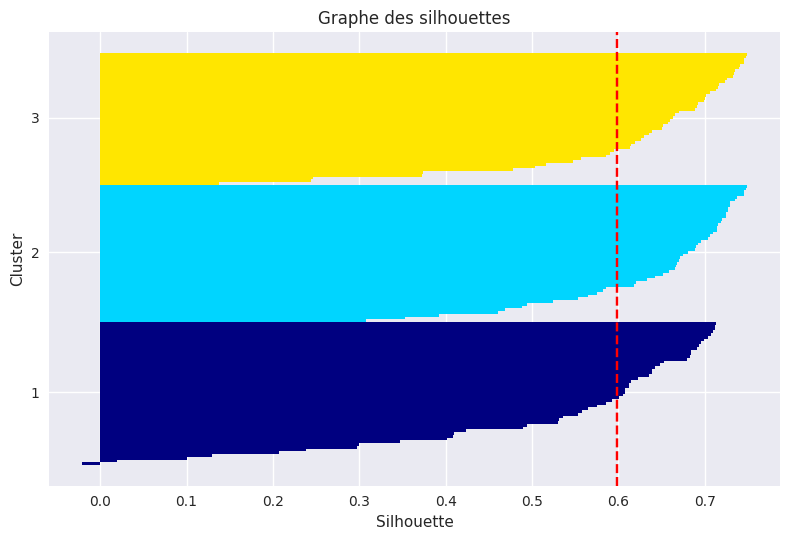

In [0]:
show_silhouettes_shapes(km,X)

### EXERCICE
- Reprendre la méthode en générant de nouvelles données en faisant varier dans *make_blobs()* le nombre de clusters (*centers*) et l'écart type (*cluster_std*)
- Conclure sur la faisabilité de la méthode

## Clustering hiérachique

### Affichage du dendogramme complet

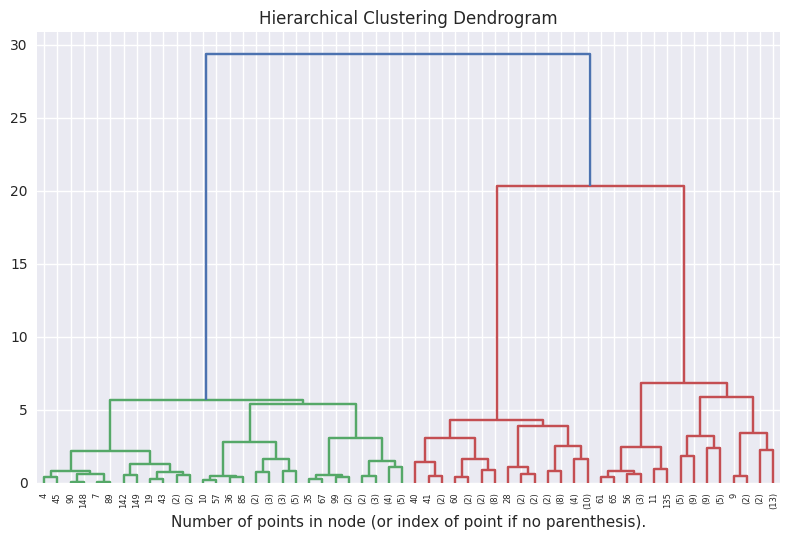

In [0]:
from sklearn.cluster import AgglomerativeClustering

# on met à 0 *distance_threshold* pour afficher le dendogramme complet
hiera = AgglomerativeClustering(distance_threshold=0, n_clusters=None)
show_dendrogram(hiera, X, level_max=5)

### Réglage du paramètre de distance
- méthode des silhouettes

#### EXERCICE 
- identifier le bon réglage du paramètre *distance_threshold* par la méthode des silhouettes avec la fonction *show_silhouette_graph()*
- afficher le clustering obtenu avec cette valeur du paramètre, à l'aide de la fonction *show_model_2D_graph()*

#### SOLUTION

- Analyser d'abord simplement la répartition des clusters en fonction du paramètre *distance_threshold*

In [0]:
tmp = []
for dist in np.arange(1., 50., 5):
    hiera.distance_threshold=dist
    y = hiera.fit_predict(X)
    unique, counts = np.unique(y, return_counts=True)
    row = []
    tmp.append([dist, hiera.n_clusters_, counts])
pd.DataFrame(tmp, columns=['distance_threshold', 'n_clusters', 'Répartition']).style.hide(axis="index")

distance_threshold,n_clusters,Répartition
1.000000,33,[ 2 10 10 10 8 5 9 6 6 6 4 4 5 2 5 3 6 2 3 5 3 3 4 3 2 5 1 4 1 4 1 4 4]
6.000000,4,[46 50 46 8]
11.000000,3,[54 50 46]
16.000000,3,[54 50 46]
21.000000,2,[100 50]
26.000000,2,[100 50]
31.000000,1,[150]
36.000000,1,[150]
41.000000,1,[150]
46.000000,1,[150]


> Si l'on peut écarter d'emblée, les valeurs extrêmes 1 et 33 clusters, la valeur du paramètre *distance_threshold* devrait se situer dans l'interval : ]1.,31[.

- Traçage du graphe des silhouettes dans l'intervalle réduit à ]1.,26.[ car on ne peut calculer des silhouettes avec 1 seul cluster

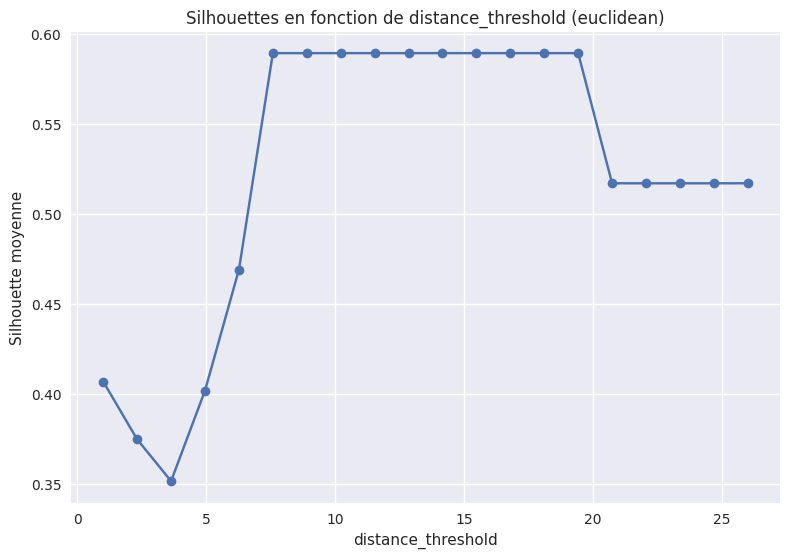

In [0]:
show_silhouette_graph(hiera, X, 'distance_threshold', 1., 26., 20)

> On observe un plateau supérieur pour des valeurs : [7,19]. On choisit par exemple 10. :

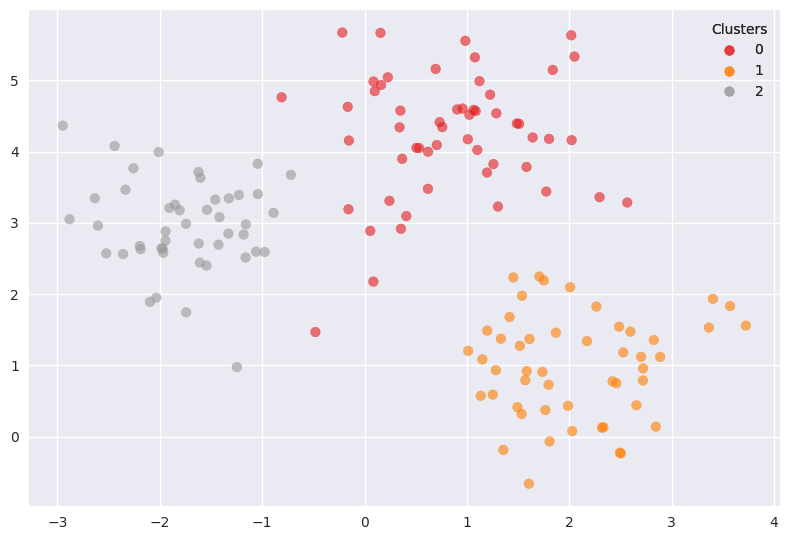

In [0]:
hiera.distance_threshold = 10.
show_model_2D_graph(hiera, X)

> ... qui donne la bonne réponse

# LE CLUSTERING NON CONVEXE

## À Bas Bruit

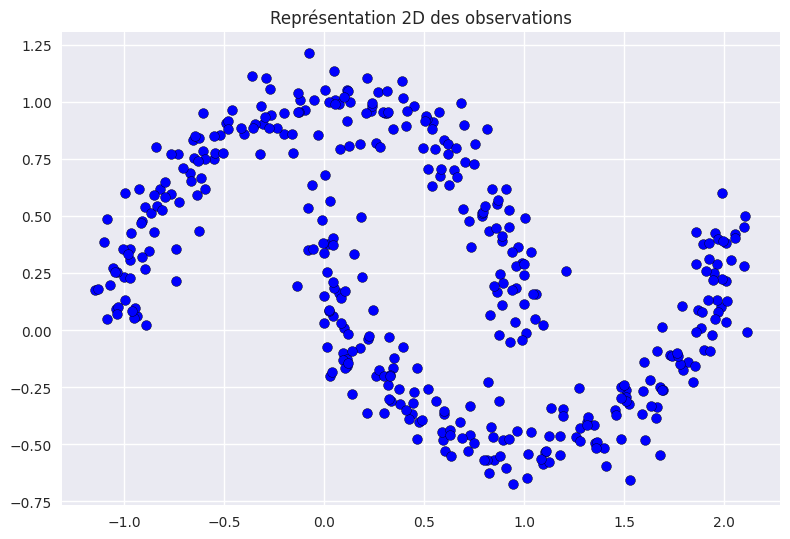

In [0]:
from sklearn.datasets import make_moons
noise = 0.09
X, _ = make_moons(n_samples=400, noise=noise, random_state=0)
show_2D_points(X[:,0], X[:,1])

### Clustering KMeans

In [0]:
from sklearn.cluster import KMeans
km = KMeans(init='k-means++', n_init=10, max_iter=300, random_state=0)

- Courbe Elbow

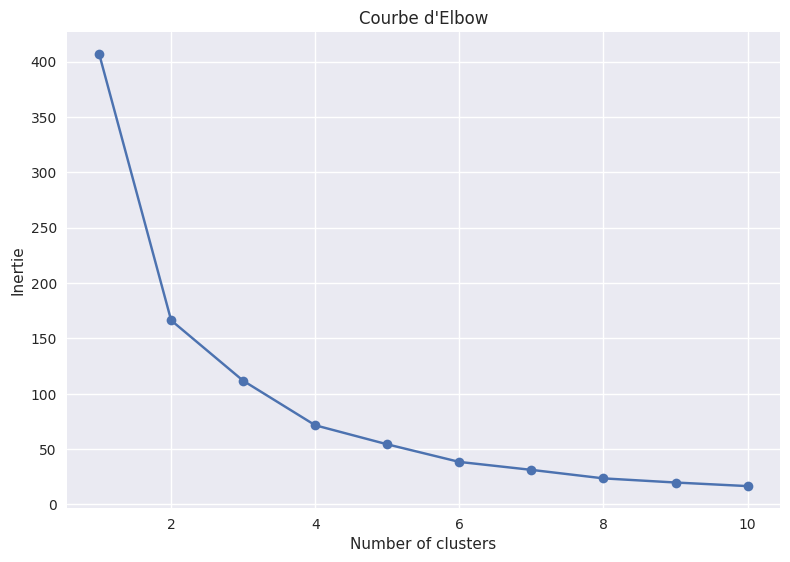

In [0]:
show_elbow_graph(km, X, 'n_clusters', 1, 11)

- Silhouettes

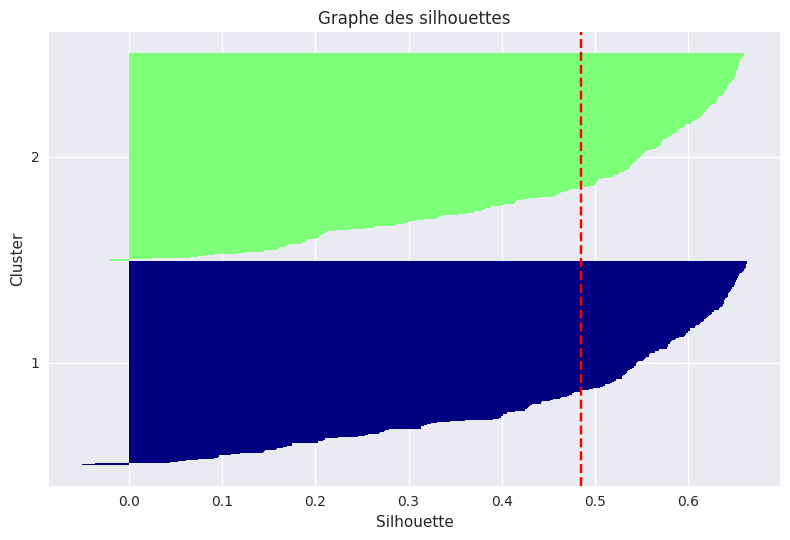

In [0]:
km.n_clusters = 2
show_silhouettes_shapes(km, X)

=> Silhouette moyenne basse

- Résultats

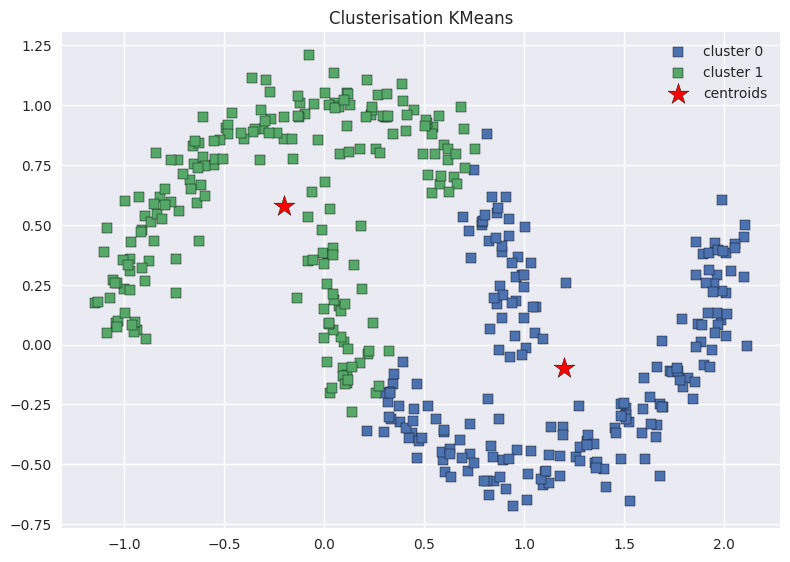

In [0]:
show_kmeans_2D_graph(km, X)

=> pas concluant (approche trop *sphérique*)

### Clustering Hiérarchique
#### Réglage par défaut

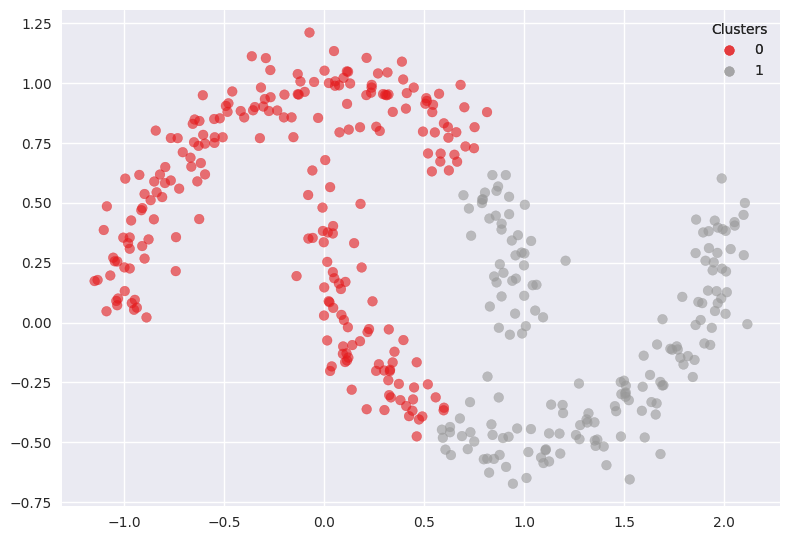

In [0]:
from sklearn.cluster import AgglomerativeClustering
hiera = AgglomerativeClustering()
show_model_2D_graph(hiera, X)

=> le paramètrage, par défaut ici, nécessite un réglage approprié

#### Sélection des paramètres à régler
- deux paramètres sont utiles : *linkage* et *distance_threshold*

In [0]:
hiera.n_clusters=None
hiera.linkage='single' # Bien adapté pour le clustering non convexe
param_name = 'distance_threshold' # Valeur du paramètre à identifier

#### Répartition clustering
- on affiche la répartition de clusters en fonction de la valeur du paramètre *distance_threshold*

In [0]:
hiera_show_repartition(np.linspace(0.07,0.2,10))

distance_threshold,n_clusters,Répartition
0.070000,103,[10 12 9 9 11 4 8 18 10 6 19 7 3 5 7 9 3 6 14 4 5 6 7 11 13 1 1 1 1 1 1 1 4 1 2 1 10 1 11 1 10 6 9 1 7 1 2 3 9 3 21 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 1 1 1 1 1 1 1 4 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 1 1 1 18]
0.084444,59,[34 15 54 21 14 21 41 1 10 1 1 31 19 11 2 1 1 1 1 1 1 1 1 1 3 3 37 1 5 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 37]
0.098889,33,[116 42 142 1 1 66 5 1 1 1 1 1 1 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
0.113333,19,[191 150 2 42 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
0.127778,11,[195 196 1 1 1 1 1 1 1 1 1]
0.142222,6,[395 1 1 1 1 1]
0.156667,3,[398 1 1]
0.171111,2,[399 1]
0.185556,1,[400]
0.200000,1,[400]


> **Observation :** Compte tenu du nombre de clusters et de leur répartition : $$distance\_threshold < 0.14$$

#### Méthode des instabilités
**Algo** :
- Génération de $n$ jeux d'observations bruitées :
$$gaussian\_noise\_multivariate = \mathcal{N}(\mu_{data},\,\frac{\sigma_{data}^{2}}{para\_div})$$
- Entraînement et prédiction du modèle de clustering et prédictions sur les n jeux
- Calcul des distances entre les prédictions entre chaque jeux :
$$ dist(i,j)= hamming(y\_pred_i, y\_pred_j), i,j=1,n ; i≠j$$
- Calcul de l'instabilité du clustering :
$$Instability =\frac{2 \times \sum_{i=1}^{n-1} \sum_{j=i}^{n} dist(i,j) }{ n^2 }$$
*Source : https://arxiv.org/abs/1007.1075*

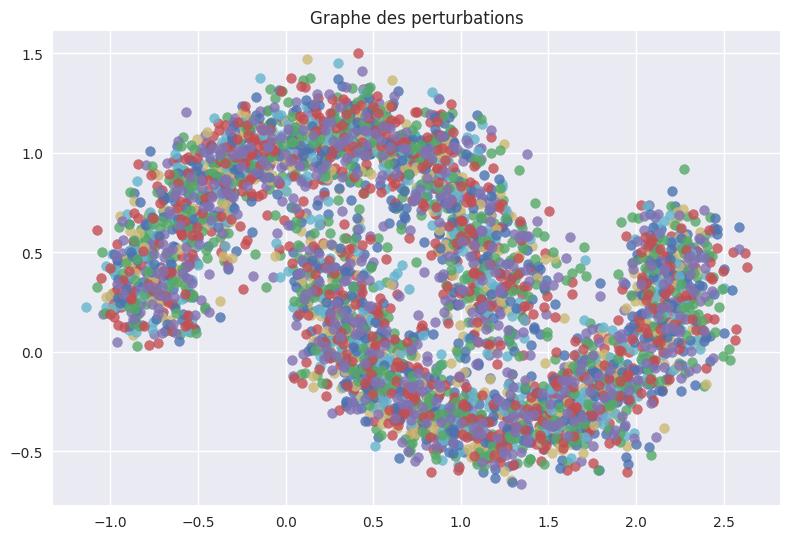

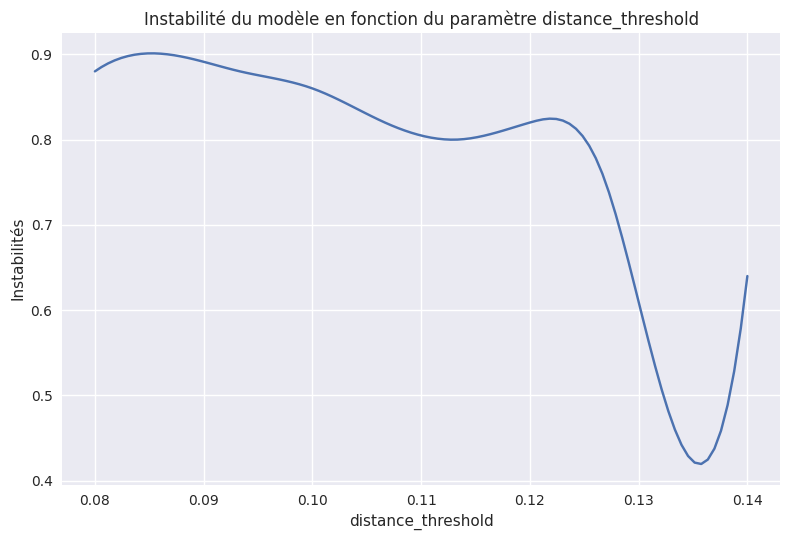

CPU times: user 955 ms, sys: 382 ms, total: 1.34 s
Wall time: 980 ms


In [0]:
%%time
param_range = np.linspace(0.08,0.14,10)
X_perturbed, instabilities, n_clusters, _= instability(
    X, hiera, param_name, param_range, cov_div=64)
show_n_2D_points(X_perturbed, title='Graphe des perturbations')
show_instability_graph(instabilities, param_name, param_range, smooth=True)

> **Observation :** Sachant que la valeur attendue doit se situer en dessous de 0.14, et que l'on observe un point bas pour une valeur comprise entre 0.13 et 0.14, on peut choisir : $$distance\_threshold \sim 0.135$$ 

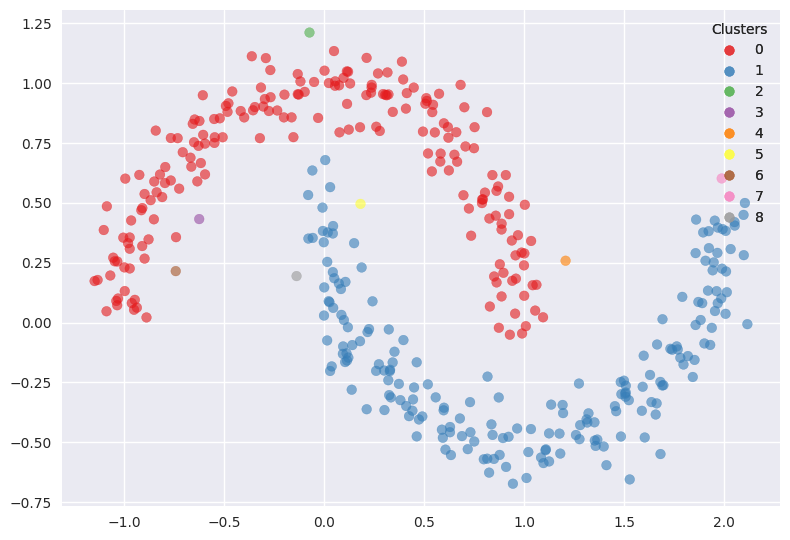

In [0]:
hiera.distance_threshold=0.135
show_model_2D_graph(hiera, X)

In [0]:
hiera_show_repartition(np.linspace(0.135,0.135,1))

distance_threshold,n_clusters,Répartition
0.135000,9,[196 197 1 1 1 1 1 1 1]


> **Conclusion :** Le clustering hiérarchique peut cerner un problème non convexe (ici à bas bruit) en choisissant un réglage *single_linkage*

## À bruit plus élevé

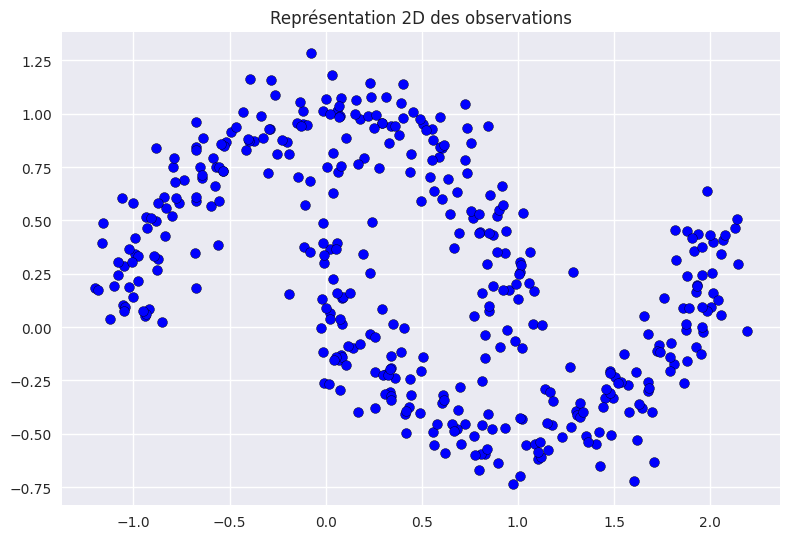

In [0]:
noise = 0.12
X, _ = make_moons(n_samples=400, noise=noise, random_state=0)
show_2D_points(X[:,0], X[:,1])

### Hiérarchical Clustering

In [0]:
hiera_show_repartition(np.linspace(0.07,0.2,10))

distance_threshold,n_clusters,Répartition
0.070000,149,[25 10 5 2 3 6 13 3 13 2 4 4 4 2 7 5 6 7 5 2 1 3 4 2 8 5 3 7 5 9 5 6 2 7 6 11 4 2 3 3 1 1 1 3 1 1 2 2 1 2 2 1 3 2 5 7 1 2 6 3 4 3 4 2 2 3 2 2 6 2 9 1 2 1 1 1 1 1 2 1 1 1 1 1 1 1 1 1 3 1 1 1 1 1 1 1 1 1 1 1 1 1 4 1 1 1 1 1 1 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 3 1 1 1 1 1 1 1 1 1 2 1 2 1 1 1 1 1 1 1 1 1 1 1 1]
0.084444,84,[35 6 16 22 14 2 9 44 38 15 3 2 1 13 2 8 4 12 29 2 12 3 1 1 1 1 1 7 5 1 3 6 2 2 2 19 1 2 2 3 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 1 1 1 1 1 1 1 1 1 1 1 2 1 2 1 1 1 1 1]
0.098889,52,[ 8 21 2 27 14 78 6 6 21 2 32 32 45 1 2 2 1 3 19 2 1 12 2 24 4 1 1 1 1 1 3 1 1 1 1 1 1 1 2 1 1 1 1 1 3 1 1 1 1 1 2 1]
0.113333,25,[192 3 87 45 2 2 1 1 47 2 3 1 1 1 1 1 1 1 2 1 1 1 1 1 1]
0.127778,14,[ 2 1 385 1 1 2 1 1 1 1 1 1 1 1]
0.142222,10,[390 1 2 1 1 1 1 1 1 1]
0.156667,8,[392 1 2 1 1 1 1 1]
0.171111,5,[ 3 394 1 1 1]
0.185556,3,[398 1 1]
0.200000,3,[398 1 1]


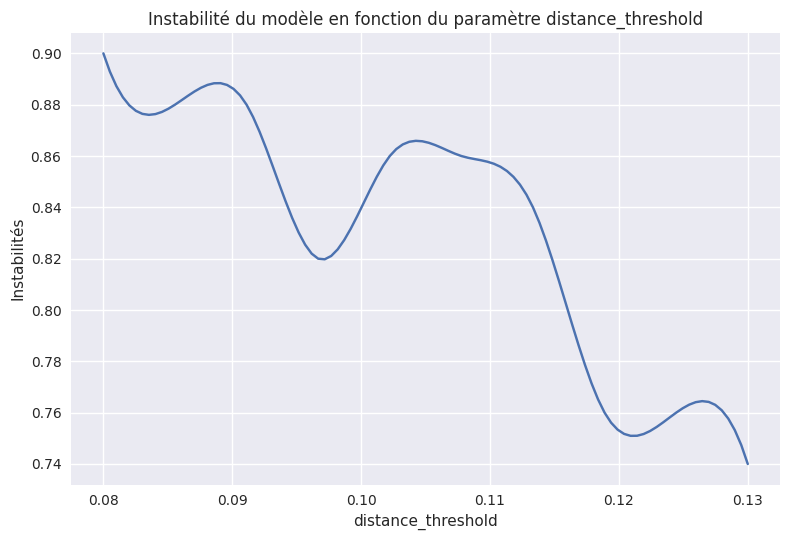

CPU times: user 858 ms, sys: 203 ms, total: 1.06 s
Wall time: 898 ms


In [0]:
%%time
param_range = np.linspace(0.08,0.13,10)
_, instabilities, _, _= instability(X, hiera, param_name, param_range, cov_div=64)
show_instability_graph(instabilities, param_name, param_range, smooth=True)

> **Observation :** Il y a un creux d'instabilité pour des valeurs :$$distance\_threshold \in [0.12,0.13]$$

In [0]:
hiera_show_repartition(np.linspace(0.12,0.13,10))

distance_threshold,n_clusters,Répartition
0.120000,21,[284 3 2 45 2 1 1 1 47 2 1 1 1 1 1 1 1 1 2 1 1]
0.121111,20,[286 3 2 45 2 1 1 1 47 1 1 1 1 1 1 1 1 1 2 1]
0.122222,19,[288 3 2 45 1 1 1 1 47 1 1 1 1 1 1 1 1 1 2]
0.123333,18,[ 92 288 2 3 1 1 1 1 2 1 1 1 1 1 1 1 1 1]
0.124444,15,[385 1 2 1 1 1 1 1 1 1 1 1 1 1 1]
0.125556,14,[ 2 1 385 1 1 2 1 1 1 1 1 1 1 1]
0.126667,14,[ 2 1 385 1 1 2 1 1 1 1 1 1 1 1]
0.127778,14,[ 2 1 385 1 1 2 1 1 1 1 1 1 1 1]
0.128889,14,[ 2 1 385 1 1 2 1 1 1 1 1 1 1 1]
0.130000,14,[ 2 1 385 1 1 2 1 1 1 1 1 1 1 1]


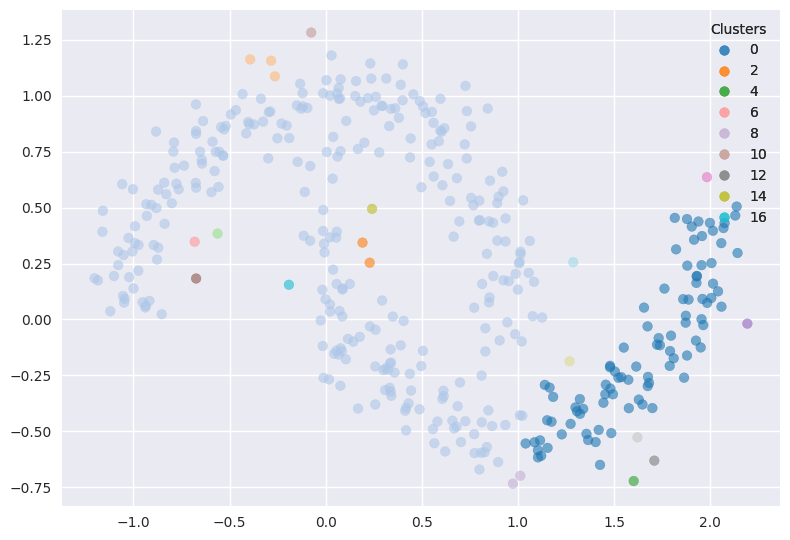

In [0]:
hiera.distance_threshold=0.12333
show_model_2D_graph(hiera, X, colormap="tab20")

> **Conclusion :** Difficile de statuer ici, l'approche hiéarchique ne permet pas de statuer précisément

### Clustering DBScan

In [0]:
from sklearn.cluster import DBSCAN
dbscan = DBSCAN()

#### Répartition du clustering
- en fonction du paramètre *eps*

In [0]:
dbscan_show_repartition(np.linspace(0.01,0.2,10))

eps,n_clusters,Répartition,Outliers
0.010000,0,[],400
0.031111,1,[5],395
0.052222,11,[6 5 5 5 5 7 5 5 6 6 5],340
0.073333,24,[ 5 11 10 10 11 6 12 13 6 6 6 7 7 5 5 5 6 8 6 10 7 5 6 7],220
0.094444,20,[70 12 12 12 39 13 10 21 6 7 19 20 7 5 11 4 11 14 11 5],91
0.115556,6,[180 45 33 51 47 5],39
0.136667,2,[194 185],21
0.157778,1,[392],8
0.178889,1,[395],5
0.200000,1,[398],2


#### Méthode des distances k-graph

>**Algo : distances k-graph**  
>- calcul de la distance moyenne de chaque observation avec ses k plus proches voisins (méthode de la classe du modèle **kNN**)
>- tri par ordre croissant des distances
>- affichage de la courbe et recherche du point de maximum de courbure (cf méthode **Elbow**) :
>    - ce point correspond au **seuil d'équilibre** entre bénéfice et perte du modèle de clustering *DBScan* pour le paramètre *eps* :
>        - pour des valeurs inférieures au seuil : on ne capte pas assez de points (on obtient trop de clusters ~underfit)
>        - pour des valeurs supérieures au seuil : on capte trop de points, y compris les points outliers (on n'obtient pas assez de clusters ~ overfit)
>*Source : d'après https://medium.com/@tarammullin/dbscan-parameter-estimation-ff8330e3a3bd*

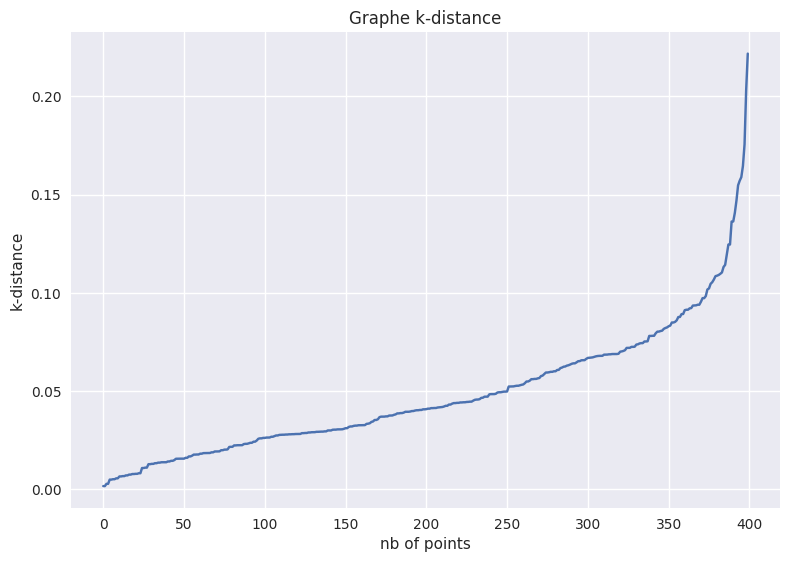

In [0]:
k_graph_dists = k_graph_dist(X)
show_k_graph_dist(k_graph_dists)

> **Observation :** Le maximum de courbure s'obtient pour l'intervalle,$$eps \in ]0.05,0.15[$$

#### Méthode des instabilités

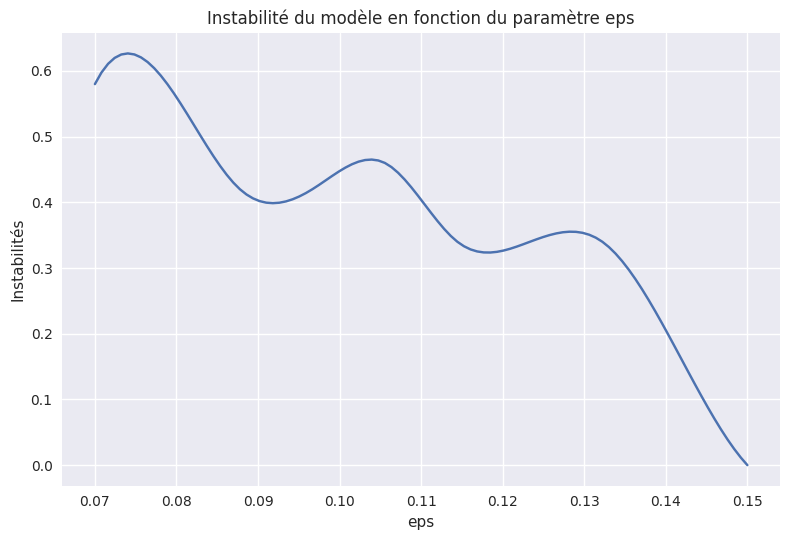

In [0]:
param_range = np.linspace(0.07,0.15,10)
param_name='eps'
_, instabilities, _, _= instability(
    X, dbscan, param_name, param_range, cov_div=64)
show_instability_graph(instabilities, param_name, param_range, smooth=True)

> **Observation :** Les instabilités décroissent linéairement, on doit prendre : $$eps \lesssim 0.15$$

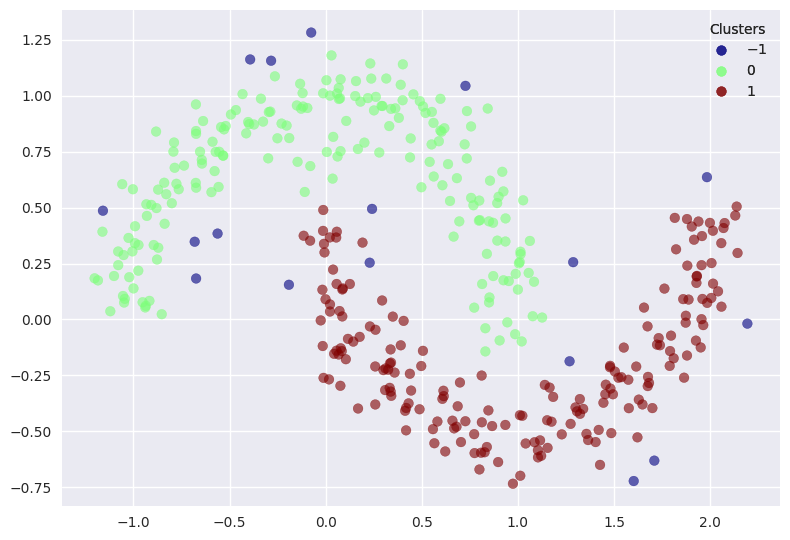

In [0]:
dbscan.eps = 0.14
show_model_2D_graph(dbscan, X, colormap='jet')

> **Conclusion :** L'algotithme DBScan réussit ici là ou le Hiérarchical Clustering a échoué, moyennant un tatonnement autour des trois méthodes : représentation statistique,distance k-graph et instabilités.

In [0]:
dbscan_show_repartition(np.linspace(0.14,0.14,1))

eps,n_clusters,Répartition,Outliers
0.140000,2,[196 187],17
